<a href="https://colab.research.google.com/github/Ankitbansal108/DSC-WebDev-Task/blob/main/energy.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
df = pd.read_excel('//dataset.xcontentlsx')
print('First 5 rows of the DataFrame:')
print(df.head())
print('\nDataFrame Info:')
df.info()
print('\nDescriptive Statistics:')
print(df.describe())

First 5 rows of the DataFrame:
             TimeStamp  Fan (kWatts)   PC (kWatts)   Air (kWatts)   \
0  12/29/2023 17:28:00         0.0270           0.0            0.0   
1  12/29/2023 17:29:00         0.0168           0.0            0.0   
2  12/29/2023 17:30:00         0.0210           0.0            0.0   
3  12/29/2023 17:31:00         0.0241           0.0            0.0   
4  12/29/2023 17:32:00         0.0218           0.0            0.0   

   Light (kWatts)   TV (kWatts)   Total Power  
0          0.0033            0.0       0.0303  
1          0.0000            0.0       0.0168  
2          0.0000            0.0       0.0210  
3          0.0000            0.0       0.0241  
4          0.0000            0.0       0.0218  

DataFrame Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6803 entries, 0 to 6802
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   TimeStamp       6803 non-null   object 
 1

In [ ]:
import numpy as np
df['TimeStamp'] = pd.to_datetime(df['TimeStamp'])
df['hour'] = df['TimeStamp'].dt.hour
df['day_of_week'] = df['TimeStamp'].dt.dayofweek
df['month'] = df['TimeStamp'].dt.month
df['day_of_year'] = df['TimeStamp'].dt.dayofyear
df = df.rename(columns={
    'Fan (kWatts)': 'Fan_kWatts',
    'PC (kWatts)': 'PC_kWatts',
    'Air (kWatts)': 'Air_kWatts',
    'Light (kWatts)': 'Light_kWatts',
    ' TV (kWatts)': 'TV_kWatts',
    'Total Power': 'Total_Power'
})
print('First 5 rows of the DataFrame after preprocessing:')
print(df.head())

print('\nDataFrame Info after preprocessing:')
df.info()

First 5 rows of the DataFrame after preprocessing:
            TimeStamp  Fan (kWatts)   PC (kWatts)   Air (kWatts)   \
0 2023-12-29 17:28:00         0.0270           0.0            0.0   
1 2023-12-29 17:29:00         0.0168           0.0            0.0   
2 2023-12-29 17:30:00         0.0210           0.0            0.0   
3 2023-12-29 17:31:00         0.0241           0.0            0.0   
4 2023-12-29 17:32:00         0.0218           0.0            0.0   

   Light_kWatts   TV (kWatts)   Total_Power  hour  day_of_week  month  \
0        0.0033            0.0       0.0303    17            4     12   
1        0.0000            0.0       0.0168    17            4     12   
2        0.0000            0.0       0.0210    17            4     12   
3        0.0000            0.0       0.0241    17            4     12   
4        0.0000            0.0       0.0218    17            4     12   

   day_of_year  
0          363  
1          363  
2          363  
3          363  
4         

In [ ]:
import re
df.columns = df.columns.str.strip()
df.columns = [re.sub(r'[^a-zA-Z0-9_]', '_', col).replace('__', '_').strip('_') for col in df.columns]
print('First 5 rows of the DataFrame after full column renaming:')
print(df.head())

print('\nDataFrame Info after full column renaming:')
df.info()

First 5 rows of the DataFrame after full column renaming:
            TimeStamp  Fan_kWatts  PC_kWatts  Air_kWatts  Light_kWatts  \
0 2023-12-29 17:28:00      0.0270        0.0         0.0        0.0033   
1 2023-12-29 17:29:00      0.0168        0.0         0.0        0.0000   
2 2023-12-29 17:30:00      0.0210        0.0         0.0        0.0000   
3 2023-12-29 17:31:00      0.0241        0.0         0.0        0.0000   
4 2023-12-29 17:32:00      0.0218        0.0         0.0        0.0000   

   TV_kWatts  Total_Power  hour  day_of_week  month  day_of_year  
0        0.0       0.0303    17            4     12          363  
1        0.0       0.0168    17            4     12          363  
2        0.0       0.0210    17            4     12          363  
3        0.0       0.0241    17            4     12          363  
4        0.0       0.0218    17            4     12          363  

DataFrame Info after full column renaming:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6

/tmp/ipython-input-1730692318.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='hour', y='Total_Power', data=avg_power_by_hour, palette='viridis')
/tmp/ipython-input-1730692318.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='day_of_week', y='Total_Power', data=avg_power_by_day, palette='plasma')


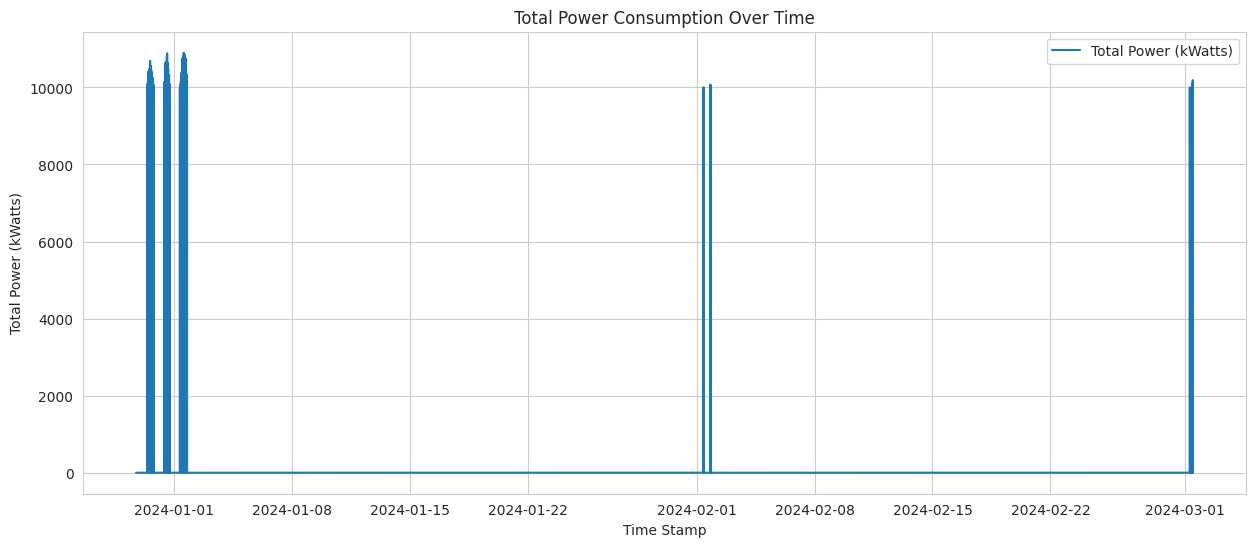

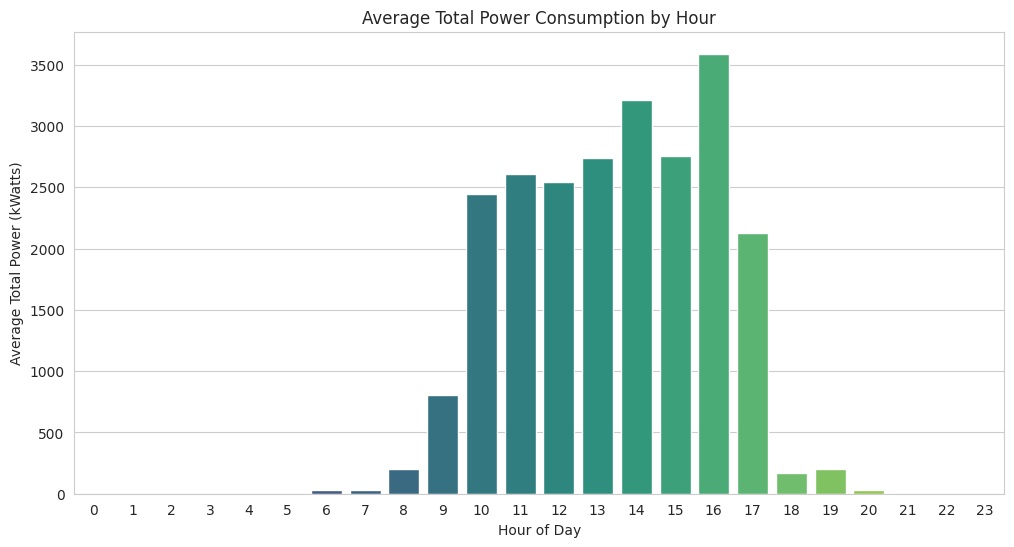

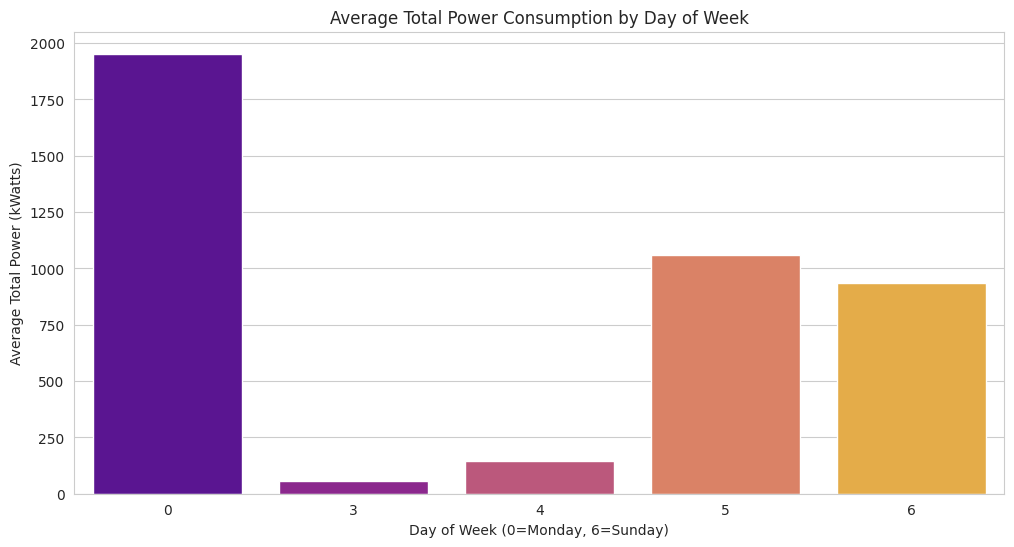

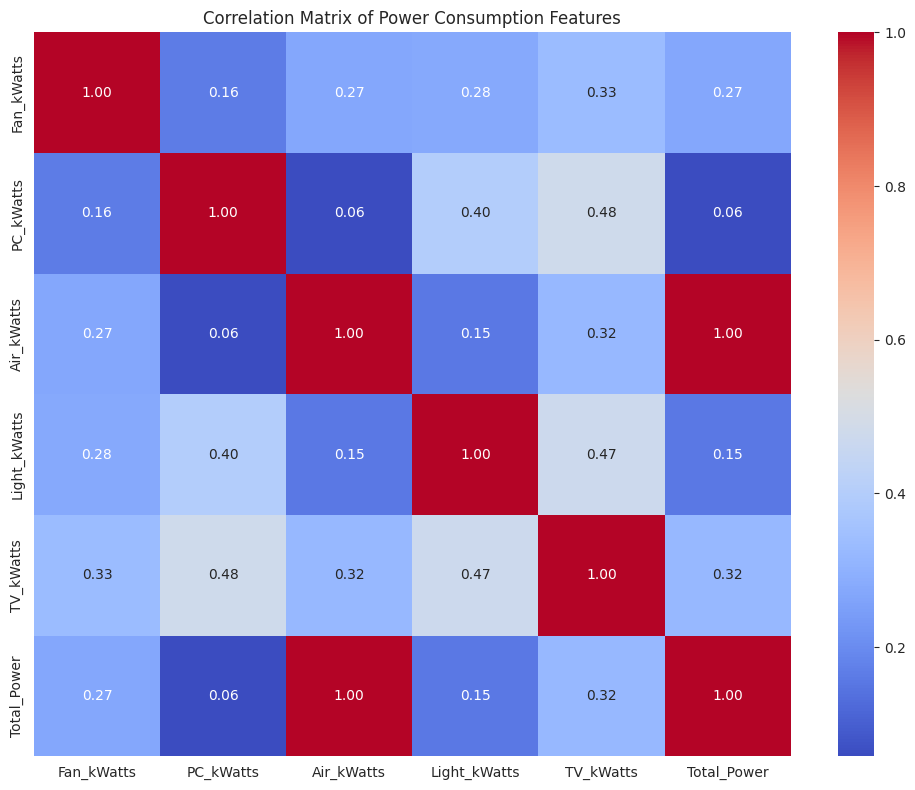

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("whitegrid")
plt.figure(figsize=(15, 6))
plt.plot(df['TimeStamp'], df['Total_Power'], label='Total Power (kWatts)')
plt.title('Total Power Consumption Over Time')
plt.xlabel('Time Stamp')
plt.ylabel('Total Power (kWatts)')
plt.legend()
plt.grid(True)

avg_power_by_hour = df.groupby('hour')['Total_Power'].mean().reset_index()
plt.figure(figsize=(12, 6))
sns.barplot(x='hour', y='Total_Power', data=avg_power_by_hour, palette='viridis')
plt.title('Average Total Power Consumption by Hour')
plt.xlabel('Hour of Day')
plt.ylabel('Average Total Power (kWatts)')

avg_power_by_day = df.groupby('day_of_week')['Total_Power'].mean().reset_index()
plt.figure(figsize=(12, 6))
sns.barplot(x='day_of_week', y='Total_Power', data=avg_power_by_day, palette='plasma')
plt.title('Average Total Power Consumption by Day of Week')
plt.xlabel('Day of Week (0=Monday, 6=Sunday)')
plt.ylabel('Average Total Power (kWatts)')

power_cols = ['Fan_kWatts', 'PC_kWatts', 'Air_kWatts', 'Light_kWatts', 'TV_kWatts', 'Total_Power']
correlation_matrix = df[power_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix of Power Consumption Features')

plt.tight_layout()
plt.show()

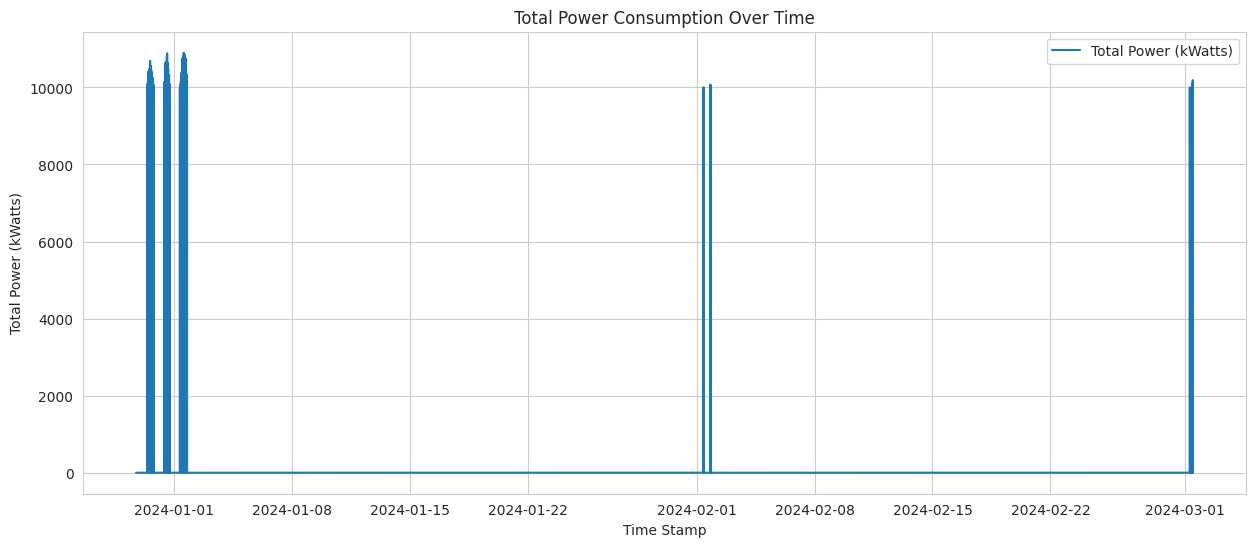

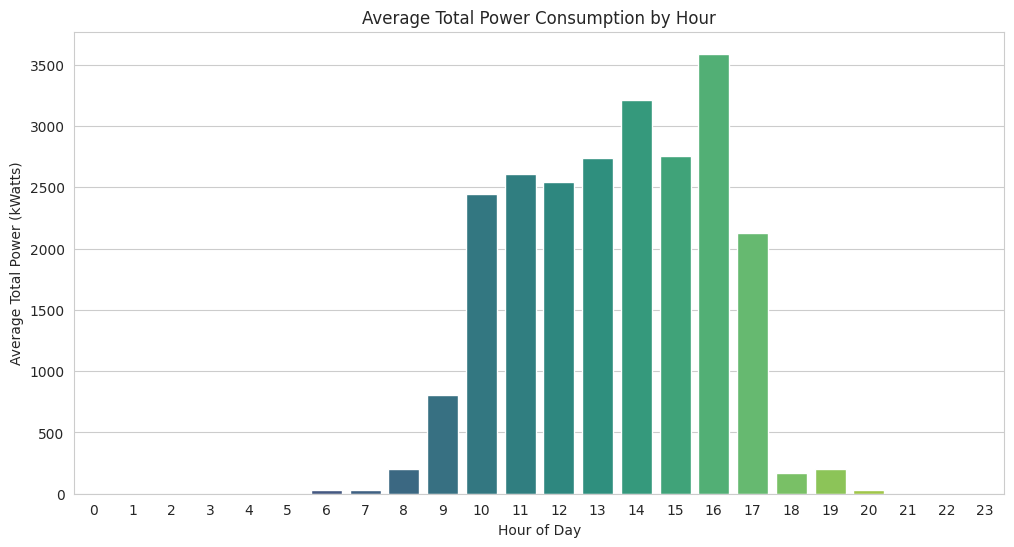

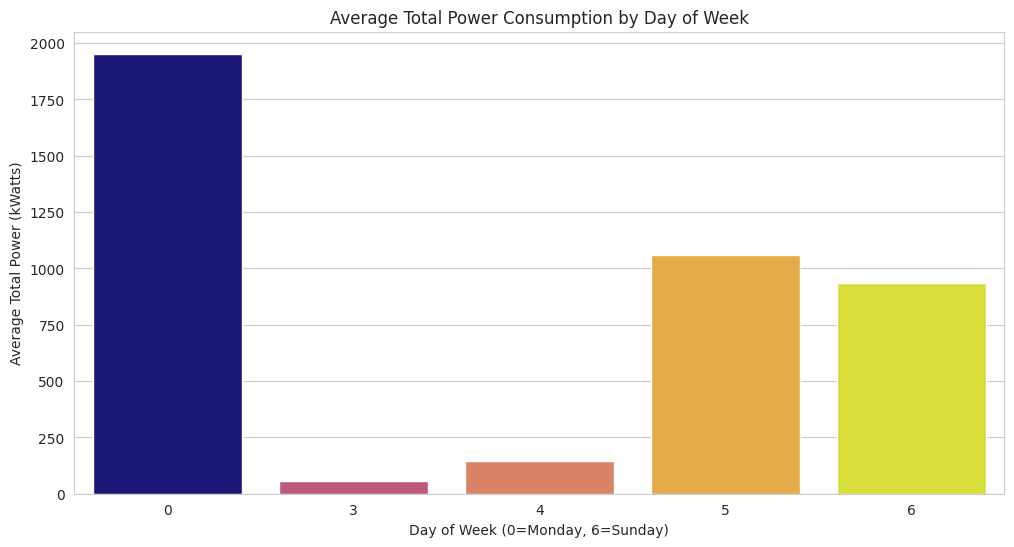

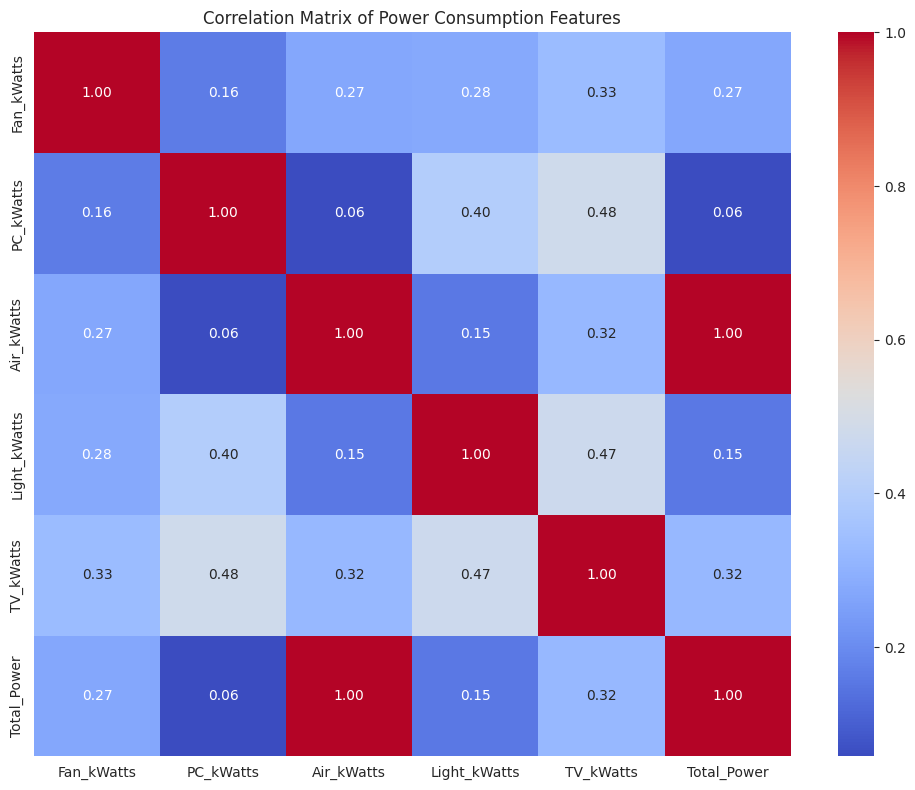

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("whitegrid")
plt.figure(figsize=(15, 6))
plt.plot(df['TimeStamp'], df['Total_Power'], label='Total Power (kWatts)')
plt.title('Total Power Consumption Over Time')
plt.xlabel('Time Stamp')
plt.ylabel('Total Power (kWatts)')
plt.legend()
plt.grid(True)
avg_power_by_hour = df.groupby('hour')['Total_Power'].mean().reset_index()
plt.figure(figsize=(12, 6))
sns.barplot(x='hour', y='Total_Power', data=avg_power_by_hour, palette='viridis', hue='hour', legend=False)
plt.title('Average Total Power Consumption by Hour')
plt.xlabel('Hour of Day')
plt.ylabel('Average Total Power (kWatts)')
avg_power_by_day = df.groupby('day_of_week')['Total_Power'].mean().reset_index()
plt.figure(figsize=(12, 6))
sns.barplot(x='day_of_week', y='Total_Power', data=avg_power_by_day, palette='plasma', hue='day_of_week', legend=False)
plt.title('Average Total Power Consumption by Day of Week')
plt.xlabel('Day of Week (0=Monday, 6=Sunday)')
plt.ylabel('Average Total Power (kWatts)')

power_cols = ['Fan_kWatts', 'PC_kWatts', 'Air_kWatts', 'Light_kWatts', 'TV_kWatts', 'Total_Power']
correlation_matrix = df[power_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix of Power Consumption Features')

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
feature_cols = ['hour', 'day_of_week', 'month', 'day_of_year',
                'Fan_kWatts', 'PC_kWatts', 'Air_kWatts', 'Light_kWatts', 'TV_kWatts']
X = df[feature_cols]
y = df['Total_Power']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape: {y_test.shape}")

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

X_train_scaled = pd.DataFrame(X_train_scaled, columns=feature_cols, index=X_train.index)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=feature_cols, index=X_test.index)

print("\nFirst 5 rows of X_train_scaled:")
print(X_train_scaled.head())

print("\nFirst 5 rows of X_test_scaled:")
print(X_test_scaled.head())

X_train shape: (5442, 9)
X_test shape: (1361, 9)
y_train shape: (5442,)
y_test shape: (1361,)

First 5 rows of X_train_scaled:
          hour  day_of_week     month  day_of_year  Fan_kWatts  PC_kWatts  \
1092 -0.046907     0.670532  1.034181     1.033210    0.706303  -0.635863   
6486 -0.894027     0.198898 -0.718184    -0.744376    0.075361  -0.635863   
124   1.082587     0.198898  1.034181     1.027343   -0.993659   1.591058   
6252 -1.458773     0.198898 -0.718184    -0.744376    0.006481  -0.635863   
5362 -0.188093    -0.272737 -0.912891    -0.914508   -1.379388  -0.635863   

      Air_kWatts  Light_kWatts  TV_kWatts  
1092   -0.300982     -0.061604   1.079281  
6486   -0.300981     -0.975723  -0.575432  
124    -0.300982      0.803104   1.213638  
6252   -0.300981     -0.975723  -0.533004  
5362   -0.300987     -0.975723  -1.678575  

First 5 rows of X_test_scaled:
          hour  day_of_week     month  day_of_year  Fan_kWatts  PC_kWatts  \
2576  0.094280     1.142166  1.034181

In [ ]:
from sklearn.ensemble import RandomForestRegressor

model = RandomForestRegressor(n_estimators=100, random_state=42)

model.fit(X_train_scaled, y_train)

print("RandomForestRegressor model trained successfully.")

RandomForestRegressor model trained successfully.


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

y_pred = model.predict(X_test_scaled)

mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print(f"Model Evaluation Metrics:")
print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"R-squared (R2) Score: {r2:.4f}")

Model Evaluation Metrics:
Mean Absolute Error (MAE): 0.1471
Mean Squared Error (MSE): 1.1144
Root Mean Squared Error (RMSE): 1.0557
R-squared (R2) Score: 1.0000


In [ ]:
import numpy as np

peak_hours = range(10, 17) on
X_test_controlled_features = X_test.copy()

is_peak_hour = X_test_controlled_features['hour'].isin(peak_hours)

reduction_percentage = 0.20
X_test_controlled_features.loc[is_peak_hour, 'Air_kWatts'] = X_test_controlled_features.loc[is_peak_hour, 'Air_kWatts'] * (1 - reduction_percentage)

X_test_controlled_scaled = scaler.transform(X_test_controlled_features)
X_test_controlled_scaled = pd.DataFrame(X_test_controlled_scaled, columns=feature_cols, index=X_test_controlled_features.index)

y_pred_uncontrolled = model.predict(X_test_scaled)
y_pred_controlled = model.predict(X_test_controlled_scaled)

print("Predictions for uncontrolled and controlled scenarios generated.")


Predictions for uncontrolled and controlled scenarios generated.


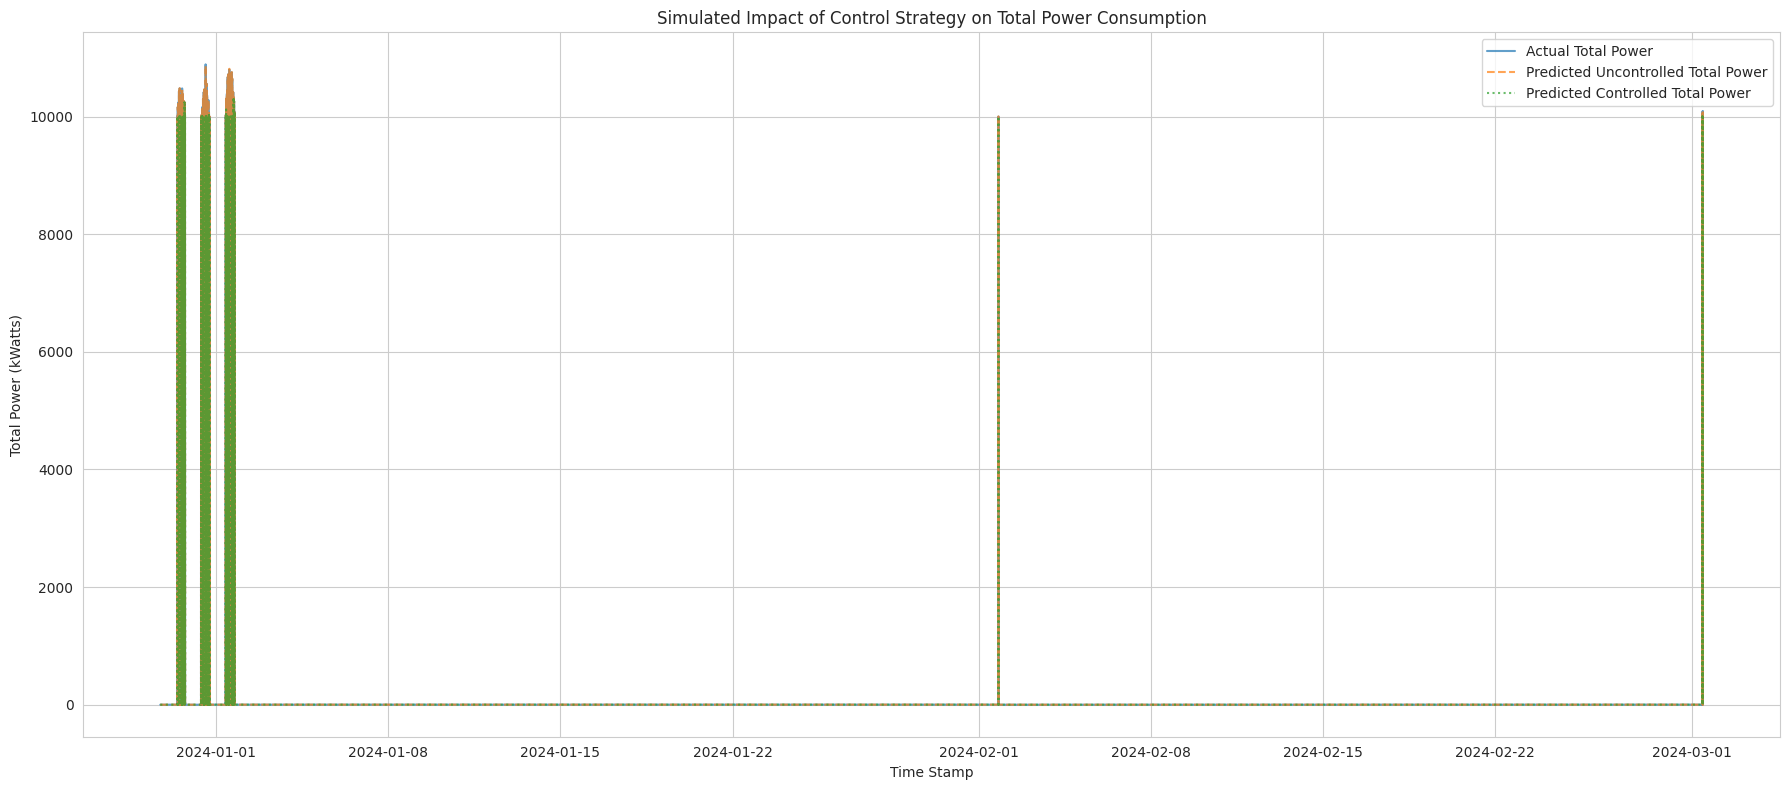


Total uncontrolled peak consumption: 998137.45 kWatts
Total controlled peak consumption: 960199.98 kWatts
Absolute reduction in peak consumption: 37937.47 kWatts
Percentage reduction in peak consumption: 3.80%


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
test_timestamps = df.loc[y_test.index, 'TimeStamp']
plot_df = pd.DataFrame({
    'TimeStamp': test_timestamps,
    'Actual_Total_Power': y_test,
    'Predicted_Uncontrolled': y_pred_uncontrolled,
    'Predicted_Controlled': y_pred_controlled
}).sort_values('TimeStamp')

plt.figure(figsize=(18, 8))
plt.plot(plot_df['TimeStamp'], plot_df['Actual_Total_Power'], label='Actual Total Power', alpha=0.7)
plt.plot(plot_df['TimeStamp'], plot_df['Predicted_Uncontrolled'], label='Predicted Uncontrolled Total Power', alpha=0.7, linestyle='--')
plt.plot(plot_df['TimeStamp'], plot_df['Predicted_Controlled'], label='Predicted Controlled Total Power', alpha=0.7, linestyle=':')

plt.title('Simulated Impact of Control Strategy on Total Power Consumption')
plt.xlabel('Time Stamp')
plt.ylabel('Total Power (kWatts)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

peak_hours_in_test_indices = X_test.loc[is_peak_hour].index

actual_peak_consumption = y_test.loc[peak_hours_in_test_indices].sum()
uncontrolled_peak_consumption = pd.Series(y_pred_uncontrolled, index=y_test.index).loc[peak_hours_in_test_indices].sum()
controlled_peak_consumption = pd.Series(y_pred_controlled, index=y_test.index).loc[peak_hours_in_test_indices].sum()

reduction_kWatts = uncontrolled_peak_consumption - controlled_peak_consumption
percentage_reduction = (reduction_kWatts / uncontrolled_peak_consumption) * 100

print(f"\nTotal uncontrolled peak consumption: {uncontrolled_peak_consumption:.2f} kWatts")
print(f"Total controlled peak consumption: {controlled_peak_consumption:.2f} kWatts")
print(f"Absolute reduction in peak consumption: {reduction_kWatts:.2f} kWatts")
print(f"Percentage reduction in peak consumption: {percentage_reduction:.2f}%")


In [ ]:
import numpy as np

peak_hours = range(10, 17)
X_test_aggressive_controlled_features = X_test.copy()

is_peak_hour_aggressive = X_test_aggressive_controlled_features['hour'].isin(peak_hours)

aggressive_reduction_percentage = 0.75
X_test_aggressive_controlled_features.loc[is_peak_hour_aggressive, 'Air_kWatts'] = X_test_aggressive_controlled_features.loc[is_peak_hour_aggressive, 'Air_kWatts'] * (1 - aggressive_reduction_percentage)

X_test_aggressive_controlled_scaled = scaler.transform(X_test_aggressive_controlled_features)
X_test_aggressive_controlled_scaled = pd.DataFrame(X_test_aggressive_controlled_scaled, columns=feature_cols, index=X_test_aggressive_controlled_features.index)

y_pred_aggressive_controlled = model.predict(X_test_aggressive_controlled_scaled)

print("Predictions for aggressive controlled scenario generated.")

Predictions for aggressive controlled scenario generated.


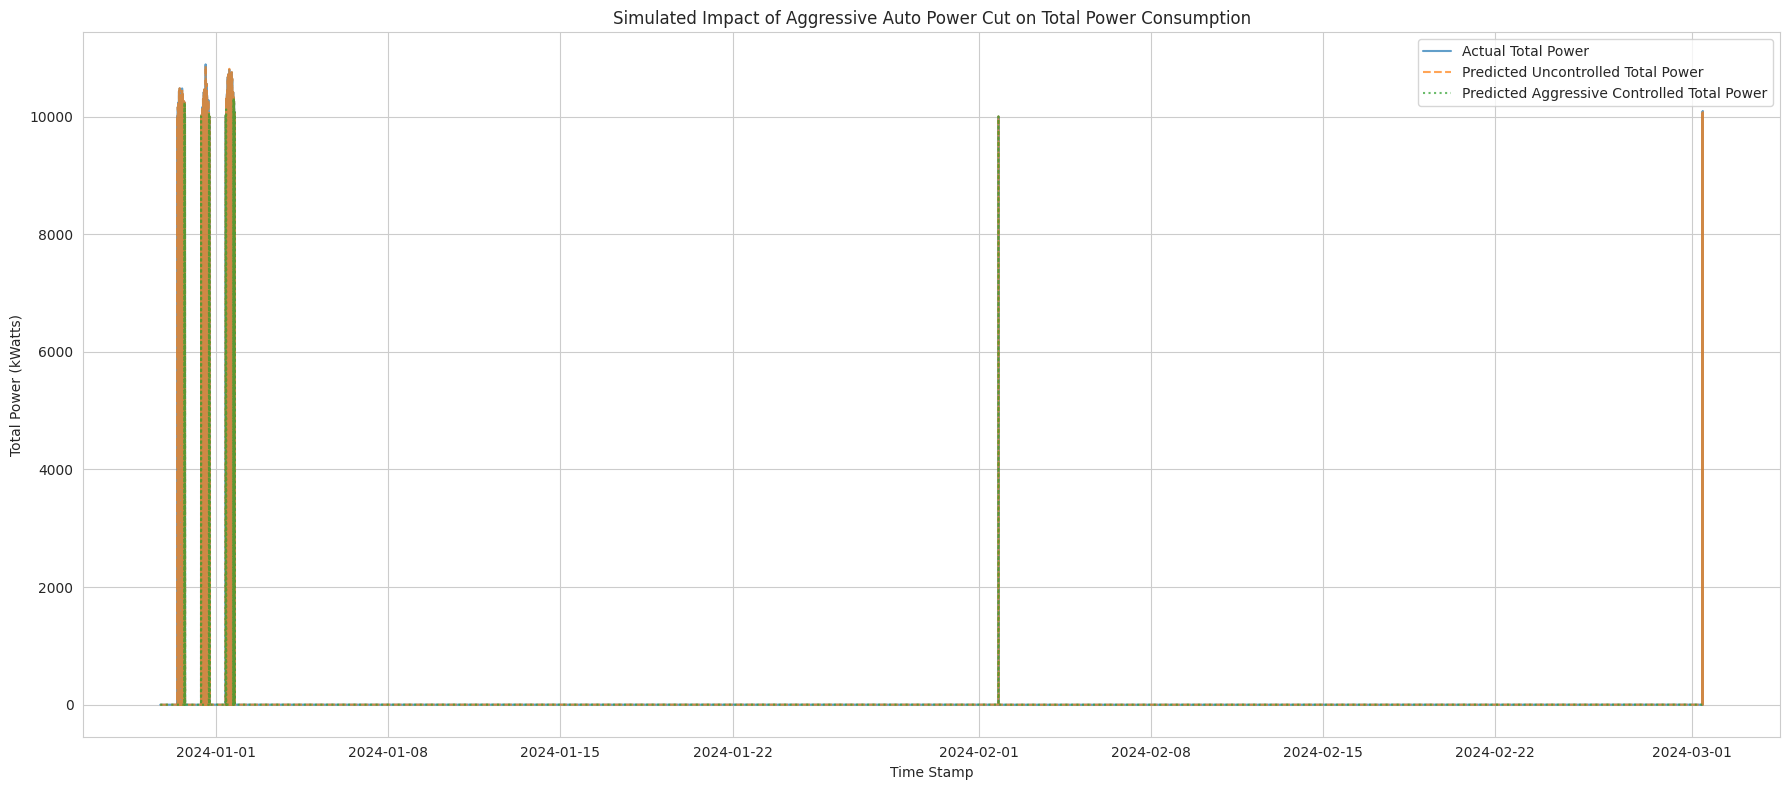


Total uncontrolled peak consumption (aggressive scenario base): 998137.45 kWatts
Total aggressive controlled peak consumption: 143.71 kWatts
Absolute reduction in peak consumption (aggressive): 997993.74 kWatts
Percentage reduction in peak consumption (aggressive): 99.99%


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
et
test_timestamps = df.loc[y_test.index, 'TimeStamp']

plot_df_aggressive = pd.DataFrame({
    'TimeStamp': test_timestamps,
    'Actual_Total_Power': y_test,
    'Predicted_Uncontrolled': y_pred_uncontrolled,
    'Predicted_Aggressive_Controlled': y_pred_aggressive_controlled
}).sort_values('TimeStamp')

plt.figure(figsize=(18, 8))
plt.plot(plot_df_aggressive['TimeStamp'], plot_df_aggressive['Actual_Total_Power'], label='Actual Total Power', alpha=0.7)
plt.plot(plot_df_aggressive['TimeStamp'], plot_df_aggressive['Predicted_Uncontrolled'], label='Predicted Uncontrolled Total Power', alpha=0.7, linestyle='--')
plt.plot(plot_df_aggressive['TimeStamp'], plot_df_aggressive['Predicted_Aggressive_Controlled'], label='Predicted Aggressive Controlled Total Power', alpha=0.7, linestyle=':')

plt.title('Simulated Impact of Aggressive Auto Power Cut on Total Power Consumption')
plt.xlabel('Time Stamp')
plt.ylabel('Total Power (kWatts)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

peak_hours_in_test_indices_aggressive = X_test.loc[is_peak_hour_aggressive].index

uncontrolled_peak_consumption_agg = pd.Series(y_pred_uncontrolled, index=y_test.index).loc[peak_hours_in_test_indices_aggressive].sum()
aggressive_controlled_peak_consumption = pd.Series(y_pred_aggressive_controlled, index=y_test.index).loc[peak_hours_in_test_indices_aggressive].sum()

reduction_kWatts_aggressive = uncontrolled_peak_consumption_agg - aggressive_controlled_peak_consumption
percentage_reduction_aggressive = (reduction_kWatts_aggressive / uncontrolled_peak_consumption_agg) * 100

print(f"\nTotal uncontrolled peak consumption (aggressive scenario base): {uncontrolled_peak_consumption_agg:.2f} kWatts")
print(f"Total aggressive controlled peak consumption: {aggressive_controlled_peak_consumption:.2f} kWatts")
print(f"Absolute reduction in peak consumption (aggressive): {reduction_kWatts_aggressive:.2f} kWatts")
print(f"Percentage reduction in peak consumption (aggressive): {percentage_reduction_aggressive:.2f}%")